# 06 · Monte Carlo: segundos contra vidas

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

**Pregunta:** en cada corredor, ¿cuántas vidas y cuántos incidentes graves al año evitaría un tope de 50 km/h (Bogotá) o un carril exclusivo de motos (Malasia), y cuántos segundos por viaje costaría?

**Plan del notebook**
1. **Insumos**, cada uno con su fuente:
   - 1.1 muertos por corredor (Distrito, 2019–2024; D17, D30);
   - 1.2 víctimas en moto por corredor (D15), para el carril de motos;
   - 1.3 incidentes graves por corredor (ITM, 2019–2024, corregidos por cobertura; D32, D35);
   - 1.4 exponente y referentes (D28, D31, D37);
   - 1.5 velocidad de día y segundos del tope (Google Traffic; D29).
2. Velocidad nocturna: factor de noche del SIMM (Johan; D34, D36).
3. Simulación del tope de 50 km/h.
4. Simulación del carril de motos en las 3 vías rápidas (D35).
5. Comparación y ranking de corredores.
6. Resumen.

**Resultado:** por vía y por medida, muertes e incidentes graves evitados por año, con mediana e intervalo de 90%, y los segundos por viaje que cuesta el tope.

Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [1]:
import os, sys, warnings
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.seguridad import mortalidad_con_corredor, victimas_con_corredor
from src.velocidad import CORREDORES

pd.set_option("display.max_columns", 40)
Path("data/processed").mkdir(parents=True, exist_ok=True)
NOMBRE = {cid: v[0] for cid, v in CORREDORES.items()}
RAPIDAS = ["AV_REGIONAL", "AUT_SUR", "AUT_NORTE"]                       # D29 y P6
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e6e5e1"
SEMILLA = 2026

def estilo(ax, eje="x"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2)
    ax.grid(axis=eje, color=GRILLA, lw=0.8); ax.set_axisbelow(True)

def franja(hora):
    """Día = 6 a 19:59 h (lo que mide Google Traffic); noche = 20 a 5:59 h. Sin hora = faltante."""
    h = pd.to_numeric(hora, errors="coerce").astype(float)
    return pd.Series(np.select([h.between(6, 19).to_numpy(), h.notna().to_numpy()], ["día", "noche"], "sin hora"), index=hora.index)

print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


## 1 · Insumos

#### 1.1 Muertos por corredor (línea base de las vidas salvadas)
- Fuente: `mortalidad_distrito`, 2019–2024, asignada con el mismo método que todo el proyecto (D17, D27, D30).
- Se separan por franja: el tope se evalúa a cualquier hora, con un factor distinto de día y de noche (D35, D36).
- Control: deben salir 294 muertos en los 12 corredores, de 1.541 en la ciudad (D30).

In [2]:
mor = mortalidad_con_corredor()
mor["ano"] = pd.to_datetime(mor["fecha"], errors="coerce").dt.year
mor = mor[mor["ano"].between(2019, 2024)].copy()
mor["franja"] = franja(mor["hora"])
anos = mor["ano"].nunique()

en_corr = mor[mor["corredor_id"].notna()]
print(f"Muertos 2019–2024: ciudad {len(mor):,} · 12 corredores {len(en_corr):,} "
      f"({len(en_corr) / len(mor) * 100:.0f}%) · control D30: 294 de 1.541")

muertos = (en_corr.groupby(["corredor_id", "franja"]).size().unstack(fill_value=0)
           .reindex(columns=["día", "noche", "sin hora"], fill_value=0))
muertos.insert(0, "muertos 2019–2024", muertos.sum(axis=1))
muertos["por año"] = muertos["muertos 2019–2024"] / anos
muertos["% de noche"] = muertos["noche"] / (muertos["día"] + muertos["noche"]) * 100
muertos = muertos.sort_values("muertos 2019–2024", ascending=False)

ciudad = mor["franja"].value_counts()
print(f"De noche (20–6 h): ciudad {ciudad.get('noche', 0) / (ciudad.get('día', 0) + ciudad.get('noche', 0)) * 100:.0f}% "
      f"· corredores {muertos['noche'].sum() / (muertos['día'].sum() + muertos['noche'].sum()) * 100:.0f}% "
      f"· sin hora: {ciudad.get('sin hora', 0)}")

muertos.to_csv("data/processed/mc_muertos_corredor.csv")
tabla = muertos.copy(); tabla.index = tabla.index.map(NOMBRE)
tabla.round(1)

mortalidad_distrito: 1541 filas leídas | duplicados exactos eliminados: 0 | sin fecha válida eliminados: 0 | final: 1541
Muertos 2019–2024: ciudad 1,541 · 12 corredores 294 (19%) · control D30: 294 de 1.541
De noche (20–6 h): ciudad 41% · corredores 49% · sin hora: 4


franja,muertos 2019–2024,día,noche,sin hora,por año,% de noche
corredor_id,,,,,,
Autopista Norte,65,30,35,0,10.8,53.8
Autopista Sur,40,23,17,0,6.7,42.5
Avenida Regional,38,18,20,0,6.3,52.6
Avenida Oriental,34,18,15,1,5.7,45.5
Avenida 80,19,8,11,0,3.2,57.9
Avenida San Juan,18,8,10,0,3.0,55.6
Avenida Ferrocarril,18,8,10,0,3.0,55.6
Avenida 33,17,9,8,0,2.8,47.1
Avenida Guayabal,17,10,7,0,2.8,41.2


**Conclusión.** Entre 2019 y 2024 murieron 1.541 personas en las vías de Medellín. 294 de ellas (19%) murieron en solo 12 corredores. Tres vías concentran casi la mitad: la Autopista Norte (65), la Autopista Sur (40) y la Regional (38) suman 143 muertes, unas 24 por año. El dato nuevo es la hora: **en los corredores, el 49% de las muertes ocurre de noche (20–6 h)**, frente al 41% en el resto de la ciudad. En la Autopista Norte (54%) y en la Regional (53%), la noche pesa más que el día, aunque por esas vías pasa unas 7 veces menos tráfico de noche. Solo 4 muertes no tienen hora.

**Decisión.** Si el tope de 50 se evaluara solo de día, quedaría por fuera la mitad de las muertes de las vías donde actúa. Como la velocidad de noche en las vías rápidas es la misma que de día (p85 noche/día de 1,00 a 1,02; D34), **el tope se evalúa a cualquier hora**, con la velocidad de día de Google Traffic y la de noche del SIMM (cierra P5). Las cifras por corredor son pequeñas (entre 0,7 y 10,8 muertes por año), así que el Monte Carlo debe mostrar las vidas salvadas con su intervalo, no como una cifra exacta.

#### 1.2 Víctimas en moto por corredor (insumo del carril de motos)
- Fuente: `victimas_con_corredor()` (Josué), 2014 – sep 2021, misma asignación que el resto (D12, D30).
- En moto = conductor de moto o parrillero. El riesgo se mide como **% de víctimas en moto**, no por millón de motos, porque el SIMM no distingue las motos (D15).
- Se calcula para todas las víctimas (heridos y muertos) y aparte para los muertos, que son pocos por corredor: por eso se muestra cuántos hay.

In [3]:
vic = victimas_con_corredor()
n_sin = vic["condicion"].isna().sum()
vic = vic[vic["condicion"].notna()].copy()
vic["moto"] = vic["condicion"].isin(["conductor_moto", "parrillero"])
vic["muerto"] = vic["gravedad_victima"].eq("muerto")
print(f"Víctimas con condición conocida: {len(vic):,} (sin condición, fuera del cálculo: {n_sin:,})")

def resumen(g):
    m = g[g["muerto"]]
    return pd.Series({"víctimas": len(g), "en moto": int(g["moto"].sum()), "% en moto": g["moto"].mean() * 100,
                      "muertos": len(m), "muertos en moto": int(m["moto"].sum()),
                      "% de los muertos en moto": m["moto"].mean() * 100 if len(m) else np.nan})

motos = vic[vic["corredor_id"].notna()].groupby("corredor_id").apply(resumen, include_groups=False)
motos.loc["CIUDAD"] = resumen(vic)
motos = motos.sort_values("% en moto", ascending=False)
motos["ranking"] = motos["% en moto"].drop("CIUDAD").rank(ascending=False, method="min")
print(f"% en moto en la ciudad: {motos.loc['CIUDAD', '% en moto']:.1f}% (D23: cerca del 75%)")

motos.to_csv("data/processed/mc_motos_corredor.csv")
tabla = motos.copy(); tabla.index = tabla.index.map(lambda c: NOMBRE.get(c, "Ciudad"))
tabla.round(1)

victimas_limpias: 1048317 leídas | filas vacías eliminadas: 812474 | sin fecha o gravedad eliminadas: 0 | final: 235843 | sin coordenadas: 22960
Víctimas con condición conocida: 235,843 (sin condición, fuera del cálculo: 0)
% en moto en la ciudad: 75.6% (D23: cerca del 75%)


,víctimas,en moto,% en moto,muertos,muertos en moto,% de los muertos en moto,ranking
corredor_id,,,,,,,
Avenida Regional,2709.0,2273.0,83.9,30.0,25.0,83.3,1.0
Autopista Sur,2003.0,1678.0,83.8,29.0,16.0,55.2,2.0
Autopista Norte,5816.0,4742.0,81.5,66.0,38.0,57.6,3.0
Avenida Las Palmas,374.0,297.0,79.4,2.0,0.0,0.0,4.0
Avenida 33,2564.0,2029.0,79.1,26.0,14.0,53.8,5.0
Avenida 80,3112.0,2435.0,78.2,21.0,5.0,23.8,6.0
Avenida San Juan,3117.0,2419.0,77.6,28.0,12.0,42.9,7.0
Avenida Guayabal,3130.0,2368.0,75.7,25.0,11.0,44.0,8.0
Ciudad,235843.0,178326.0,75.6,1949.0,883.0,45.3,NaN


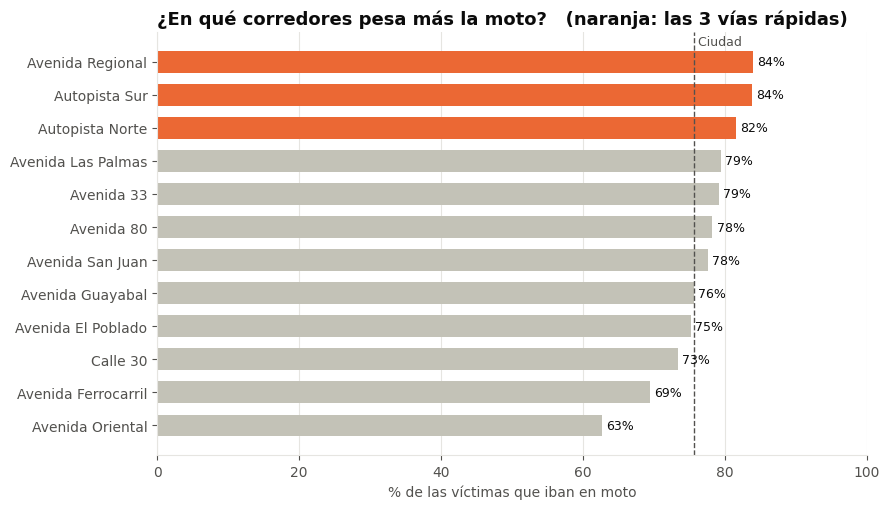

In [4]:
t = motos.drop("CIUDAD").sort_values("% en moto")
fig, ax = plt.subplots(figsize=(9, 5.2))
colores = [NARANJA if c in RAPIDAS else GRIS for c in t.index]
ax.barh(t.index.map(NOMBRE), t["% en moto"], color=colores, height=0.65)
ax.axvline(motos.loc["CIUDAD", "% en moto"], color=TINTA_2, lw=1, ls="--")
ax.text(motos.loc["CIUDAD", "% en moto"], len(t) - 0.4, " Ciudad", color=TINTA_2, fontsize=9, va="center")
for i, v in enumerate(t["% en moto"]):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", fontsize=9, color=TINTA)
ax.set_xlim(0, 100); ax.set_xlabel("% de las víctimas que iban en moto", color=TINTA_2)
ax.set_title("¿En qué corredores pesa más la moto?   (naranja: las 3 vías rápidas)", loc="left",
             fontsize=13, weight="bold", color=TINTA)
estilo(ax); plt.tight_layout(); plt.show()

**Muertos en moto por año en las 3 vías rápidas** (lo que el carril de motos puede reducir): muertos por año del Distrito (1.1) × % de los muertos que iban en moto (1.2). Es el insumo de la sección 4; la reducción de Malasia (25–34%, D31) se aplica allá, con su incertidumbre.

In [5]:
base = pd.DataFrame({
    "muertos por año (Distrito)": muertos.loc[RAPIDAS, "por año"],
    "% de los muertos en moto": motos.loc[RAPIDAS, "% de los muertos en moto"],
    "muertos en el cálculo del %": motos.loc[RAPIDAS, "muertos"],
})
base["muertos en moto por año"] = base["muertos por año (Distrito)"] * base["% de los muertos en moto"] / 100
base.loc["Total"] = [base["muertos por año (Distrito)"].sum(), np.nan, base["muertos en el cálculo del %"].sum(),
                     base["muertos en moto por año"].sum()]
base.to_csv("data/processed/mc_base_carril_motos.csv")
base.index = base.index.map(lambda c: NOMBRE.get(c, c))
base.round(1)

,muertos por año (Distrito),% de los muertos en moto,muertos en el cálculo del %,muertos en moto por año
corredor_id,,,,
Avenida Regional,6.3,83.3,30.0,5.3
Autopista Sur,6.7,55.2,29.0,3.7
Autopista Norte,10.8,57.6,66.0,6.2
Total,23.8,NaN,125.0,15.2


**Conclusión (base del carril).** En las 3 vías rápidas mueren unas 24 personas por año (Distrito, 2019–2024), y unas **15 de ellas van en moto**: 6,2 en la Autopista Norte, 5,3 en la Regional y 3,7 en la Autopista Sur. Ese es el techo de lo que el carril de motos puede reducir.

**Decisión.** Esta es la base de la sección 4. Se declaran dos supuestos:
- Mezcla periodos: los muertos son de 2019–2024 y la proporción de moto es de 2014–2021, porque no hay una sola fuente que traiga las dos cosas.
- El referente de Malasia (25–34%) mide accidentes de moto, no muertes. Aplicarlo a las muertes supone que bajan en la misma proporción.

Los dos supuestos van al Monte Carlo como incertidumbre, no como cifras fijas.

#### 1.3 Incidentes graves por corredor (la otra mitad del resultado)
- Fuente: base del ITM, 2019–2024, solo heridos y muertos (D8), con la misma asignación que el resto del proyecto (D27, D30).
- Cada incidente se corrige por la cobertura de coordenadas de su mes (D32): pesa 1 / cobertura.
- Se separan en día y noche, como los muertos de la 1.1.
- Los incidentes graves con moto se estiman con el % de víctimas en moto de la 1.2, porque el ITM no marca si había una moto (`hay_moto` está vacía). Es una aproximación: un incidente puede tener varias víctimas.

In [6]:
from src.seguridad import limpiar_itm
from src.corredores import asignar_corredor

itm = limpiar_itm()
itm["fecha"] = pd.to_datetime(itm["fecha"], errors="coerce")
itm = itm[itm["fecha"].dt.year.between(2019, 2024)].copy()
itm["periodo"] = itm["fecha"].dt.to_period("M")

# D32: cobertura de coordenadas de cada mes, en toda la ciudad
cobertura = itm.groupby("periodo")["lat"].apply(lambda s: s.notna().mean())

asig = asignar_corredor(itm)
asig = asig[asig["corredor_id"].notna()].copy()
asig["peso"] = 1 / asig["periodo"].map(cobertura)
asig["franja"] = franja(asig["hora"])
anos_itm = asig["fecha"].dt.year.nunique()
print(f"Graves 2019–2024: ciudad {len(itm):,} · 12 corredores {len(asig):,} registrados "
      f"({len(asig) / len(itm) * 100:.1f}%) · {asig['peso'].sum():,.0f} corregidos por cobertura")

graves = (asig.pivot_table(index="corredor_id", columns="franja", values="peso", aggfunc="sum", fill_value=0)
          .reindex(columns=["día", "noche", "sin hora"], fill_value=0))
graves.insert(0, "graves 2019–2024", graves.sum(axis=1))
graves.insert(1, "registrados", asig.groupby("corredor_id").size())
graves["por año"] = graves["graves 2019–2024"] / anos_itm
graves["% de noche"] = graves["noche"] / (graves["día"] + graves["noche"]) * 100
graves["graves por muerto"] = graves["graves 2019–2024"] / muertos["muertos 2019–2024"]
graves["letalidad noche / día"] = ((muertos["noche"] / graves["noche"]) / (muertos["día"] / graves["día"]))
graves["% en moto (víctimas, 1.2)"] = motos["% en moto"]
graves["graves con moto por año"] = graves["por año"] * graves["% en moto (víctimas, 1.2)"] / 100
graves = graves.sort_values("graves 2019–2024", ascending=False)

print(f"De noche (20–6 h): {graves['noche'].sum() / (graves['día'].sum() + graves['noche'].sum()) * 100:.0f}% "
      f"de los graves en los corredores, contra 49% de los muertos (1.1)")
graves.to_csv("data/processed/mc_graves_corredor.csv")

base_graves = graves.loc[RAPIDAS, ["por año", "% en moto (víctimas, 1.2)", "graves con moto por año"]].copy()
base_graves.loc["Total"] = [base_graves["por año"].sum(), np.nan, base_graves["graves con moto por año"].sum()]
base_graves.to_csv("data/processed/mc_base_carril_motos_graves.csv")

tabla = graves.copy(); tabla.index = tabla.index.map(NOMBRE)
display(tabla.round(1))
base_graves.index = base_graves.index.map(lambda c: NOMBRE.get(c, c))
base_graves.round(1)

limpiar_itm: coordenadas fuera de Medellín (pasan a vacío): 0
incidentes_limpios: 702540 leídas | eliminadas (sin fecha o sin gravedad): 0 | final: 702540 | sin coordenadas: 44785 | sin dirección: 15365
limpiar_itm: 702540 incidentes -> 403135 graves (se quitan 299405 de solo daños)
limpiar_itm: coordenadas repetidas más de 100 veces: 677 (138005 incidentes)
lat       lon       
6.276994  -75.572664    1553
6.265727  -75.575023    1131
6.260355  -75.573188     883
6.186616  -75.656601     823
6.273374  -75.592978     817
6.265181  -75.571703     765
6.248540  -75.580890     751
6.275406  -75.573746     707
6.269632  -75.576185     685
6.265556  -75.575333     685
6.270373  -75.573835     665
6.217069  -75.586457     664
6.303399  -75.561550     656
6.263626  -75.596980     643
6.268109  -75.576809     636
Graves 2019–2024: ciudad 140,019 · 12 corredores 19,794 registrados (14.1%) · 21,075 corregidos por cobertura
De noche (20–6 h): 24% de los graves en los corredores, contra 49% de los

franja,graves 2019–2024,registrados,día,noche,sin hora,por año,% de noche,graves por muerto,letalidad noche / día,"% en moto (víctimas, 1.2)",graves con moto por año
corredor_id,,,,,,,,,,,
Autopista Norte,4927.0,4640,3713.7,1213.4,0,821.2,24.6,75.8,3.6,81.5,669.5
Autopista Sur,1952.1,1842,1493.7,458.4,0,325.3,23.5,48.8,2.4,83.8,272.6
Avenida Oriental,1939.9,1822,1468.6,471.3,0,323.3,24.3,57.1,2.6,62.6,202.5
Avenida San Juan,1838.7,1721,1368.8,469.9,0,306.4,25.6,102.1,3.6,77.6,237.8
Avenida 80,1712.1,1605,1311.0,401.1,0,285.4,23.4,90.1,4.5,78.2,223.3
Avenida Guayabal,1670.6,1563,1270.6,399.9,0,278.4,23.9,98.3,2.2,75.7,210.6
Avenida Regional,1633.0,1532,1280.8,352.2,0,272.2,21.6,43.0,4.0,83.9,228.4
Avenida 33,1583.7,1489,1200.4,383.3,0,263.9,24.2,93.2,2.8,79.1,208.9
Avenida El Poblado,1439.4,1354,1106.9,332.6,0,239.9,23.1,143.9,2.2,75.3,180.5


franja,por año,"% en moto (víctimas, 1.2)",graves con moto por año
corredor_id,,,
Avenida Regional,272.2,83.9,228.4
Autopista Sur,325.3,83.8,272.6
Autopista Norte,821.2,81.5,669.5
Total,1418.7,NaN,1170.5


**Conclusión (1.3).** Entre 2019 y 2024 hubo unos 21.000 incidentes graves en los 12 corredores (corregidos por cobertura, D32), unos 3.500 por año. La cifra coincide con los ~3.455 del último año del notebook 05.
- **La Autopista Norte es otro nivel:** 821 incidentes graves por año, 2,5 veces los de la Autopista Sur (325) o la Oriental (323).
- **De noche ocurre solo el 24% de los incidentes graves, pero el 49% de los muertos (1.1).** En casi todos los corredores, un incidente de noche es entre 2 y 4,5 veces más letal que uno de día (Las Palmas y Ferrocarril tienen pocos casos y se salen del rango).
- **En las vías rápidas, cada incidente grave mata más.** En la Regional hay 1 muerto por cada 43 incidentes graves y en la Autopista Sur 1 por cada 49. En arterias como El Poblado (144) o San Juan (102) la proporción es dos o tres veces menor. La Oriental (57) y la Ferrocarril (50) también salen altas, probablemente por los peatones del centro (1.2).
- **En las 3 vías rápidas hay unos 1.419 incidentes graves por año, y en unos 1.170 hay una moto.** Esa es la base del carril de motos para los incidentes graves.

**Decisión (D35).** El Monte Carlo da dos resultados por medida: muertes evitadas e incidentes graves evitados. En el carril de motos, el referente de Malasia se aplica directo a los incidentes graves con moto, porque mide accidentes. Aplicado a las muertes, supone que bajan en la misma proporción. Se declara un supuesto: los incidentes graves con moto se estiman con el % de víctimas en moto, porque el ITM no marca la moto.

#### 1.4 Exponente y referentes (D28, D31, D37)
- **Incidentes graves:** en cada simulación, el exponente se sortea uniforme entre un **piso** (bootstrap del modelo C del notebook 03, cortado en 0) y un **techo** (Elvik 2009 urbano, 1,5 con IC 0,9–2,1).
- **Muertes:** exponente de graves + letalidad, sorteada uniforme entre 0 y 2 (D26).
- **Sensibilidad:** Nilsson clásico, 2 para incidentes con heridos y 4 para mortales.
- **Carril de motos:** reducción uniforme entre 25% y 34% (Malasia).
- **Bogotá (−22% a −37%)** no entra a la simulación: es la prueba de sensatez del resultado.
- 10.000 simulaciones con semilla fija (2026), para que el resultado se pueda reproducir.

In [7]:
ruta = Path("data/processed/betas_bootstrap.npy")
if not ruta.exists():
    raise FileNotFoundError("Falta data/processed/betas_bootstrap.npy: corre la sección del bootstrap del notebook 03.")

rng = np.random.default_rng(SEMILLA)
N = 10_000
boot_C = np.load(ruta)

piso = np.maximum(rng.choice(boot_C, N), 0)                         # Medellín, modelo C, cortado en 0
techo = np.clip(rng.normal(1.5, (2.1 - 0.9) / 3.92, N), 0, None)    # Elvik urbano, graves
beta_graves = piso + rng.uniform(0, 1, N) * (techo - piso)
letalidad = rng.uniform(0, 2, N)                                    # D26
beta_muertes = beta_graves + letalidad
malasia = rng.uniform(0.25, 0.34, N)

np.savez("data/processed/mc_parametros.npz", beta_graves=beta_graves, beta_muertes=beta_muertes,
         malasia=malasia, semilla=SEMILLA)

def fila(x, fuente):
    return {"p5": np.percentile(x, 5), "mediana": np.median(x), "p95": np.percentile(x, 95), "fuente": fuente}

parametros = pd.DataFrame({
    "piso (Medellín, modelo C ≥ 0)": fila(piso, "notebook 03, bootstrap por corredor"),
    "techo (Elvik urbano, graves)": fila(techo, "Elvik 2009 vía SWOV 2012"),
    "exponente · incidentes graves": fila(beta_graves, "uniforme entre piso y techo (D37)"),
    "letalidad": fila(letalidad, "uniforme 0–2 (D26)"),
    "exponente · muertes": fila(beta_muertes, "graves + letalidad (D37)"),
    "reducción · carril de motos": fila(malasia, "Malasia, Radin Umar et al. 1995"),
}).T
for col in ("p5", "mediana", "p95"):
    parametros[col] = parametros[col].astype(float).round(2)
parametros.loc["sensibilidad · Nilsson"] = ["—", "2 (graves) · 4 (muertes)", "—", "Nilsson 1982, 2004"]
parametros.loc["prueba de sensatez · Bogotá"] = ["—", "−22% a −37% de muertes", "—", "Secretaría de Movilidad, GRSF"]
print(f"Simulaciones: {N:,} · el piso de Medellín es 0 en el {np.mean(piso == 0) * 100:.0f}% de ellas")
parametros

Simulaciones: 10,000 · el piso de Medellín es 0 en el 84% de ellas


,p5,mediana,p95,fuente
"piso (Medellín, modelo C ≥ 0)",0.0,0.0,0.17,"notebook 03, bootstrap por corredor"
"techo (Elvik urbano, graves)",0.99,1.5,2.0,Elvik 2009 vía SWOV 2012
exponente · incidentes graves,0.08,0.72,1.55,uniforme entre piso y techo (D37)
letalidad,0.1,0.99,1.9,uniforme 0–2 (D26)
exponente · muertes,0.54,1.75,2.98,graves + letalidad (D37)
reducción · carril de motos,0.25,0.29,0.34,"Malasia, Radin Umar et al. 1995"
sensibilidad · Nilsson,—,2 (graves) · 4 (muertes),—,"Nilsson 1982, 2004"
prueba de sensatez · Bogotá,—,−22% a −37% de muertes,—,"Secretaría de Movilidad, GRSF"


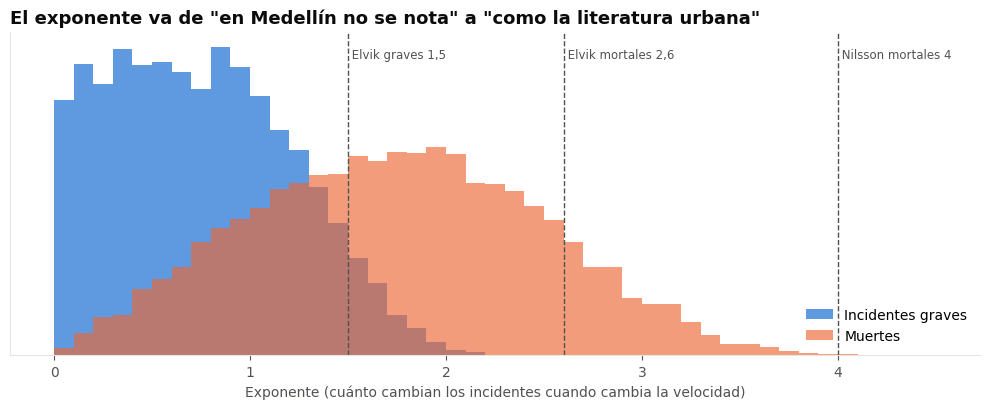

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.linspace(0, 4.5, 46)
ax.hist(beta_graves, bins=bins, color=AZUL, alpha=0.75, label="Incidentes graves")
ax.hist(beta_muertes, bins=bins, color=NARANJA, alpha=0.65, label="Muertes")
for v, txt in [(1.5, "Elvik graves 1,5"), (2.6, "Elvik mortales 2,6"), (4, "Nilsson mortales 4")]:
    ax.axvline(v, color=TINTA_2, lw=1, ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.95, f" {txt}", fontsize=8.5, color=TINTA_2, va="top")
ax.set_xlabel("Exponente (cuánto cambian los incidentes cuando cambia la velocidad)", color=TINTA_2)
ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("El exponente va de \"en Medellín no se nota\" a \"como la literatura urbana\"",
             loc="left", fontsize=13, weight="bold", color=TINTA)
estilo(ax, eje="x"); ax.grid(False); plt.tight_layout(); plt.show()

**Conclusión.** Las 10.000 simulaciones cubren desde "en Medellín la velocidad no se nota" hasta "se comporta como la literatura urbana", sin favorecer ningún extremo.
- **Piso de Medellín:** vale 0 en el 84% de las simulaciones y no pasa de 0,17. Con la hora como control (modelo C del notebook 03), los datos de Medellín no logran mostrar el efecto de la velocidad.
- **Exponente de los incidentes graves:** mediana de 0,72 (de 0,08 a 1,55), entre ese piso y el techo de Elvik (1,5).
- **Exponente de las muertes:** mediana de 1,75 (de 0,54 a 2,98). Queda por debajo del 2,6 de Elvik para siniestros mortales, y muy por debajo del 4 de Nilsson, que casi nunca se alcanza.
- **Carril de motos:** reduce entre 25% y 34%, con mediana de 29%.

**Decisión (D37).** Este rango es **conservador a propósito**: la evidencia local es débil (notebook 03) y la cuarentena solo va en la dirección esperada (notebook 04), así que no suponemos el efecto más fuerte de la literatura. Nilsson se reporta aparte, como el techo. Bogotá no entra a la simulación; sirve para revisar si el resultado es sensato.

#### 1.5 Velocidad de día y segundos del tope (notebook 03, sección 5; D29)
- Fuente: `tiempo_viaje_gt()` (Johan): Google Traffic 2017–2019, de 6:00 a 19:59 (la franja de día de este notebook).
- **Registro por registro:** con el tope, cada registro pasa de *v* a min(*v*, 50). La reducción de incidentes es 1 − promedio de (min(*v*, 50) / *v*) elevado al exponente, ponderando cada hora por los incidentes graves de día que ocurren a esa hora en el corredor (1.3).
- **Segundos extra por viaje** = longitud del tramo × (1 / min(*v*, 50) − 1 / *v*), en segundos.
- Las cifras de este cuadro usan exponentes fijos (Elvik y Nilsson) solo como lectura. El Monte Carlo usa los 10.000 exponentes de la 1.4.
- Pueden diferir un poco de D29 (57, 17 y 4 s), porque aquí el día termina a las 19:59 y no a las 20:59.

In [10]:
from src.velocidad import tiempo_viaje_gt
from src.corredores import geometria_corredores

ruta_cat = Path("data/processed/catalogo_corredores.csv")
cat = pd.read_csv(ruta_cat) if ruta_cat.exists() else None
if cat is None or "longitud_km" not in cat or cat["longitud_km"].isna().any():
    cat = geometria_corredores(itm)[0]
L_km = cat.set_index("corredor_id")["longitud_km"]

tv = tiempo_viaje_gt()
tv["ano"] = pd.to_datetime(tv["fecha"]).dt.year
tv = tv[tv["ano"].between(2017, 2019) & tv["hora"].between(6, 19) & (tv["velocidad_gt_kmh"] > 0)
        & tv["corredor_id"].isin(RAPIDAS)].copy()
v = tv["velocidad_gt_kmh"]
tv["factor_v"] = np.minimum(v, 50) / v
tv["seg_extra"] = (tv["corredor_id"].map(L_km) * 3600 * (1 / np.minimum(v, 50) - 1 / v)).clip(lower=0)

# cuándo ocurren los incidentes graves de día en cada corredor (1.3): peso de cada hora
de_dia = asig[asig["franja"] == "día"].assign(hora=lambda d: d["hora"].astype(int))
peso_h = de_dia.groupby(["corredor_id", "hora"])["peso"].sum().rename("peso_hora").reset_index()
tv = tv.merge(peso_h, on=["corredor_id", "hora"], how="left")
tv["peso_hora"] = tv["peso_hora"].fillna(0) + 0.5

# distribución del factor de velocidad en cada vía (se agrupa a 3 decimales para simular rápido)
dist_v = {}
for c in RAPIDAS:
    d = tv[tv["corredor_id"] == c]
    g = d.groupby(d["factor_v"].round(3))["peso_hora"].sum()
    dist_v[c] = (g.index.to_numpy(dtype=float), (g / g.sum()).to_numpy())

def reduccion(c, beta):
    """Reducción (0 a 1) de incidentes con el tope, para uno o varios exponentes."""
    f, w = dist_v[c]
    b = np.atleast_1d(np.asarray(beta, dtype=float))
    return 1 - (f[None, :] ** b[:, None]) @ w

filas = []
for c in RAPIDAS:
    d = tv[tv["corredor_id"] == c]
    filas.append({"corredor": NOMBRE[c], "longitud (km)": L_km[c], "registros GT": len(d),
                  "% registros > 50": (d["factor_v"] < 1).mean() * 100,
                  "segundos por viaje · día": d["seg_extra"].mean(),
                  "segundos · peor 10% del día": d["seg_extra"].quantile(0.9),
                  "graves · Elvik 1,5 (%)": reduccion(c, 1.5)[0] * 100,
                  "muertes · Elvik 2,6 (%)": reduccion(c, 2.6)[0] * 100,
                  "graves · Nilsson 2 (%)": reduccion(c, 2)[0] * 100,
                  "muertes · Nilsson 4 (%)": reduccion(c, 4)[0] * 100})
dia_tabla = pd.DataFrame(filas).set_index("corredor")
segundos = pd.DataFrame({"día": dia_tabla["segundos por viaje · día"].values}, index=RAPIDAS)
dia_tabla.to_csv("data/processed/mc_dia_tope.csv")
print("Reducción de día con exponentes fijos (lectura); el Monte Carlo usa los de la 1.4")
dia_tabla.round(1)

Reducción de día con exponentes fijos (lectura); el Monte Carlo usa los de la 1.4


,longitud (km),registros GT,% registros > 50,segundos por viaje · día,segundos · peor 10% del día,"graves · Elvik 1,5 (%)","muertes · Elvik 2,6 (%)",graves · Nilsson 2 (%),muertes · Nilsson 4 (%)
corredor,,,,,,,,,
Avenida Regional,6.6,13199,68.0,56.7,115.5,17.0,26.3,21.5,35.3
Autopista Sur,6.5,13195,37.2,15.7,57.5,4.8,7.8,6.3,11.1
Autopista Norte,5.3,13190,20.9,4.5,18.2,1.9,3.1,2.4,4.4


**Conclusión (1.5).** Los segundos que cuesta el tope de día coinciden con el notebook 03 (D29). En la Regional son **57 s por viaje** (116 s en el peor 10% de las horas), en la Autopista Sur **16 s** (58 s) y en la Autopista Norte **4,5 s** (18 s). El costo sigue al exceso: la Regional pasa de 50 en el 68% de los registros, la Autopista Sur en el 37% y la Autopista Norte en el 21%.

Con exponentes fijos, como primera lectura, la Regional es la única vía donde el tope cambia mucho:
- **Regional:** con Elvik urbano, sus incidentes graves bajarían 17% y sus muertes 26%, **dentro del rango de Bogotá (−22% a −37%)**. Con Nilsson, 21% y 35%.
- **Autopista Sur:** 5% y 8% con Elvik, 6% y 11% con Nilsson.
- **Autopista Norte:** 2% y 3% con Elvik, 2% y 4% con Nilsson.

**Decisión.** Esta distribución de velocidades por vía, ponderada por la hora en que ocurren los incidentes, es la que usa el Monte Carlo con los 10.000 exponentes de la 1.4. En la Autopista Norte el beneficio puede estar subestimado: calculando por sentido, Johan encuentra más horas sobre 50 (25–36%, D39).

**Perfil de las víctimas (D24).** El plan inicial usaba el modelo logístico para pasar de incidentes graves a muertes según quién se accidenta en cada corredor. Ya no hace falta: la línea base de muertes sale directamente de los muertos del Distrito en cada corredor (1.1), que ya reflejan su perfil. El logístico se queda en el notebook final para contar **a quién** protege cada medida (peatón ×3,4, ciclista ×2,8, 60+ ×5,7; D23).

## 2 · Velocidad nocturna (D21, D34, D36)
- Fuente: `velocidad_nocturna_corredor()` y `perfil_horario_corredor()` de Johan: SIMM, jul–ago 2020, ponderado por intensidad.
- El SIMM y Google Traffic no miden lo mismo (velocidad puntual por carril frente a velocidad media del tramo), así que **no se usan los niveles del SIMM**, solo cuánto cambian de noche.
- **Factor de noche** = % de la intensidad sobre 50 km/h de noche / de día. El efecto del tope de noche será el de día (Google Traffic) × este factor (D36).

In [11]:
from src.velocidad import velocidad_nocturna_corredor

noct = velocidad_nocturna_corredor()        # descarga y limpia el SIMM (D21); guarda también el perfil por hora
perfil = pd.read_csv("data/processed/perfil_horario_corredor.csv")

t = noct.pivot(index="corredor_id", columns="franja", values="pct_sobre_50")
fac = pd.DataFrame({"% sobre 50 de día (SIMM)": t["dia"], "% sobre 50 de noche (SIMM)": t["noche"]})
fac["factor de noche"] = (t["noche"] / t["dia"]).replace([np.inf, -np.inf], np.nan)
razones = noct.groupby("corredor_id")[["razon_noche_dia_p85", "razon_noche_dia_media"]].first()
fac["p85 noche/día"] = razones["razon_noche_dia_p85"]
fac["media noche/día"] = razones["razon_noche_dia_media"]
fac["entra al Monte Carlo"] = fac.index.isin(RAPIDAS)
fac = fac.sort_values("% sobre 50 de día (SIMM)", ascending=False)

fac.loc[RAPIDAS, ["factor de noche"]].to_csv("data/processed/mc_factor_noche.csv")
print("Factor de noche de las 3 vías rápidas:",
      {NOMBRE[c]: round(float(fac.loc[c, "factor de noche"]), 2) for c in RAPIDAS})

tabla = fac.copy(); tabla.index = tabla.index.map(NOMBRE)
tabla.round(2)

velocidad_simm: 431,490 filas
sensores_simm(): 303 sensores con corredor_id; 0 no aparecen en velocidad_simm

Filtros:
  sin corredor_id (no son uno de los 12 corredores): 203,985 filas fuera
  quedan 227,505 filas de los 12 corredores

Distribución de 'operacion' (sin filtrar), filas de los 12 corredores:
operacion
interrumpido       107173
continuo            75013
seminterrumpido     28431
NaN                 16888

  filtro velocidad faltante o no numérica (no está en D21; no se puede ponderar): quita 0 filas
  filtro velocidad_km_h == 0: quita 3,363 filas
  filtro velocidad_km_h > 150: quita 24 filas
  filtro intensidad <= 0 o faltante: quita 37 filas
  quedan 224,081 filas

velocidad_simm_limpia: 224,081 filas · día 131,561 · noche 92,520 · fechas 2020-07-01 a 2020-08-31
Factor de noche de las 3 vías rápidas: {'Avenida Regional': 0.85, 'Autopista Sur': 0.97, 'Autopista Norte': 1.18}


,% sobre 50 de día (SIMM),% sobre 50 de noche (SIMM),factor de noche,p85 noche/día,media noche/día,entra al Monte Carlo
corredor_id,,,,,,
Avenida Regional,31.15,26.61,0.85,1.02,0.94,True
Avenida Las Palmas,20.46,10.28,0.50,0.85,0.86,False
Autopista Norte,17.56,20.77,1.18,1.02,0.96,True
Autopista Sur,16.08,15.60,0.97,1.00,1.00,True
Avenida El Poblado,13.41,10.88,0.81,0.90,1.00,False
Avenida Guayabal,9.04,3.36,0.37,0.96,0.88,False
Avenida Ferrocarril,7.91,16.68,2.11,1.16,0.97,False
Avenida Oriental,0.32,0.03,0.09,1.00,0.95,False
Avenida 80,0.25,0.11,0.46,0.83,0.86,False


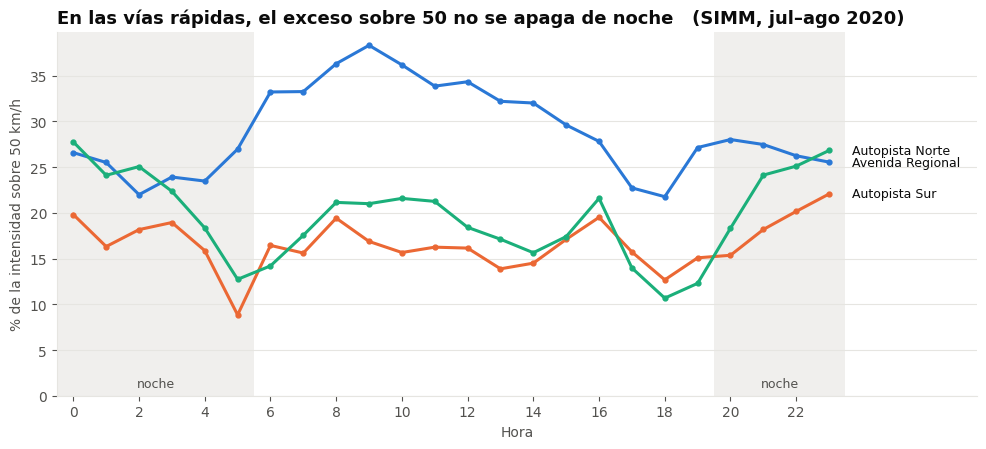

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for x0, x1 in [(-0.5, 5.5), (19.5, 23.5)]:
    ax.axvspan(x0, x1, color=GRILLA, alpha=0.6, lw=0)
ax.text(2.5, 1, "noche", ha="center", color=TINTA_2, fontsize=9)
ax.text(21.5, 1, "noche", ha="center", color=TINTA_2, fontsize=9)
for c, color in zip(RAPIDAS, [AZUL, NARANJA, "#1baf7a"]):
    d = perfil[perfil["corredor_id"] == c].sort_values("hora")
    ax.plot(d["hora"], d["pct_sobre_50"], color=color, lw=2.2, marker="o", ms=3.5)
    ax.text(23.7, d["pct_sobre_50"].iloc[-1], NOMBRE[c], va="center", fontsize=9, color=TINTA)
ax.set_xlim(-0.5, 27.5); ax.set_ylim(bottom=0)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora", color=TINTA_2)
ax.set_ylabel("% de la intensidad sobre 50 km/h", color=TINTA_2)
ax.set_title("En las vías rápidas, el exceso sobre 50 no se apaga de noche   (SIMM, jul–ago 2020)",
             loc="left", fontsize=13, weight="bold", color=TINTA)
estilo(ax, eje="y"); plt.tight_layout(); plt.show()

**Conclusión.** En las 3 vías rápidas, el exceso sobre 50 km/h no desaparece de noche. Entre las 0 y las 4 a. m. sigue pasando de 50 entre el 15% y el 28% de la intensidad medida, y de 20 a 23 h vuelve a subir. Los momentos con menos exceso son las 5 a. m. y las 6 p. m., las horas de más tráfico, cuando el trancón frena a todos.
- **Autopista Norte:** de noche se excede un poco más que de día (factor 1,18: 20,8% frente a 17,6%).
- **Autopista Sur:** igual de día y de noche (0,97).
- **Regional:** de noche se excede algo menos (0,85). Aun así sigue siendo la vía con más exceso a cualquier hora (26,6% de noche).

En las arterias, el % sobre 50 es tan bajo (menos del 1% en 6 de ellas) que sus factores no significan nada. Calle 30 sale con 3,45 porque pasa de 0,24% a 0,82%. Ninguna de esas vías entra al Monte Carlo. Las Palmas reduce su exceso a la mitad de noche (0,50).

**Decisión (D36).** El efecto del tope de noche en cada vía rápida es el efecto de día (Google Traffic, notebook 03) multiplicado por su factor: 1,18 en la Autopista Norte, 0,97 en la Autopista Sur y 0,85 en la Regional. Así, la noche entra al Monte Carlo sin mezclar los niveles de dos fuentes que miden cosas distintas. Los niveles del SIMM no se usan: son de 2020, en pandemia, y miden la velocidad en un punto, no en el tramo.

## 3 · Simulación del tope de 50 km/h (Regional, Autopista Sur, Autopista Norte)
En cada una de las 10.000 simulaciones:
1. Se sortean los exponentes de la 1.4.
2. **Reducción de día** = la de la 1.5 con ese exponente. **Reducción de noche** = la de día × factor de noche de la vía (D36).
3. Se sortea la línea base de cada franja con su incertidumbre: muertes y graves por año ~ Gamma(casos observados, 1 / años). Con pocos muertos por vía, esto pesa.
4. **Evitados** = base de día × reducción de día + base de noche × reducción de noche, para muertes (exponente de muertes) y para incidentes graves (exponente de graves).

**Escenario (D38):** tope de 50 km/h **con control permanente** (cámaras de fotodetección, o puestos de control con multas como en Bogotá en 2018). Con control, el cumplimiento es alto pero no total: se sortea **entre 85% y 100%** (supuesto nuestro, no una cifra verificada) y la reducción se multiplica por él. Los segundos son los de quien cumple el tope.

Se reporta la mediana y el intervalo de 90% (percentiles 5 y 95).

In [14]:
rng3 = np.random.default_rng(SEMILLA + 3)
cumplimiento = rng3.uniform(0.85, 1.0, N)          # D38: tope con control permanente (supuesto nuestro)
segundos["noche"] = segundos["día"] * fac.loc[RAPIDAS, "factor de noche"].astype(float).values   # D36

def gamma_anual(n, anos, r):
    """Tasa anual con su incertidumbre, a partir de n casos en `anos` años."""
    return r.gamma(max(float(n), 0.5), 1 / anos, N)

def ic(x, dec=1):
    return f"{np.median(x):.{dec}f} ({np.percentile(x, 5):.{dec}f} a {np.percentile(x, 95):.{dec}f})"

tope = {}
for c in RAPIDAS:
    fn = float(fac.loc[c, "factor de noche"])
    rg_d, rm_d = reduccion(c, beta_graves) * cumplimiento, reduccion(c, beta_muertes) * cumplimiento
    rg_n, rm_n = np.clip(rg_d * fn, 0, 0.95), np.clip(rm_d * fn, 0, 0.95)
    m_d = gamma_anual(muertos.loc[c, "día"], anos, rng3)
    m_n = gamma_anual(muertos.loc[c, "noche"] + muertos.loc[c, "sin hora"], anos, rng3)
    g_d = gamma_anual(graves.loc[c, "día"], anos_itm, rng3)
    g_n = gamma_anual(graves.loc[c, "noche"] + graves.loc[c, "sin hora"], anos_itm, rng3)
    tope[c] = {"muertes": m_d * rm_d + m_n * rm_n, "graves": g_d * rg_d + g_n * rg_n,
               "base_muertes": m_d + m_n, "base_graves": g_d + g_n}
    tope[c]["pct_muertes"] = tope[c]["muertes"] / tope[c]["base_muertes"]
    tope[c]["pct_graves"] = tope[c]["graves"] / tope[c]["base_graves"]
tope["TOTAL"] = {k: sum(tope[c][k] for c in RAPIDAS) for k in ("muertes", "graves", "base_muertes", "base_graves")}
tope["TOTAL"]["pct_muertes"] = tope["TOTAL"]["muertes"] / tope["TOTAL"]["base_muertes"]
tope["TOTAL"]["pct_graves"] = tope["TOTAL"]["graves"] / tope["TOTAL"]["base_graves"]

res_tope = pd.DataFrame({
    NOMBRE.get(c, "Total 3 vías"): {
        "muertes evitadas por año": ic(r["muertes"]),
        "% de las muertes": ic(r["pct_muertes"] * 100, 0),
        "incidentes graves evitados por año": ic(r["graves"], 0),
        "% de los graves": ic(r["pct_graves"] * 100, 0),
        "segundos por viaje (día · noche)": (f"{segundos.loc[c, 'día']:.0f} · {segundos.loc[c, 'noche']:.0f}"
                                             if c in RAPIDAS else "—"),
    } for c, r in tope.items()}).T
p1 = np.mean(tope["TOTAL"]["muertes"] >= 1) * 100
print(f"Mediana (intervalo de 90%) · probabilidad de salvar al menos 1 vida al año en las 3 vías: {p1:.0f}%")
res_tope

Mediana (intervalo de 90%) · probabilidad de salvar al menos 1 vida al año en las 3 vías: 81%


,muertes evitadas por año,% de las muertes,incidentes graves evitados por año,% de los graves,segundos por viaje (día · noche)
Avenida Regional,1.0 (0.4 a 1.7),16 (6 a 25),22 (3 a 43),8 (1 a 16),57 · 48
Autopista Sur,0.3 (0.1 a 0.6),5 (2 a 8),7 (1 a 15),2 (0 a 5),16 · 15
Autopista Norte,0.2 (0.1 a 0.4),2 (1 a 4),7 (1 a 15),1 (0 a 2),4 · 5
Total 3 vías,1.6 (0.6 a 2.6),7 (2 a 11),37 (4 a 73),3 (0 a 5),—


**Conclusión.** Con control permanente, el tope de 50 km/h en las 3 vías rápidas evitaría **1,6 muertes por año** (intervalo de 90%: 0,6 a 2,6) y **37 incidentes graves por año** (4 a 73). La probabilidad de salvar al menos una vida al año es del **81%**.
- **Casi todo el beneficio está en la Regional:** 1 muerte evitada por año (0,4 a 1,7), el **16% de sus muertes** (6% a 25%), y 22 incidentes graves (3 a 43). El costo es de 57 s por viaje de día y 48 s de noche. El rango de Bogotá (−22% a −37%) cae en la parte alta del intervalo. Tiene sentido que el resultado quede algo por debajo: el rango del exponente es conservador a propósito (D37), y en Bogotá el límite bajó de 60 a 50 en toda la vía, mientras que aquí solo actúa donde hoy se pasa de 50.
- **Autopista Sur:** 0,3 muertes por año (5%) y 7 incidentes graves, por 16 s por viaje.
- **Autopista Norte:** 0,2 muertes por año (2%), por 4 s por viaje. Allí se muere más gente que en cualquier otro corredor, pero casi nadie pasa de 50 (21% de los registros), así que el tope cambia poco. Calculado por sentido, el beneficio podría ser algo mayor (D39).
- **De noche, el tope pesa igual o más:** la mitad de los muertos de estas vías ocurre de noche (1.1), y allí el exceso sobre 50 se mantiene (sección 2).

**Decisión.** El tope se recomienda **primero en la Regional**: concentra dos tercios del beneficio y cuesta menos de un minuto por viaje. En la Autopista Norte, el tope por sí solo no ataca su problema principal. Ese es el lugar para comparar con el carril de motos (sección 4).

## 4 · Simulación del carril exclusivo de motos (3 vías rápidas; D35)
En cada simulación:
1. Reducción de Malasia ~ uniforme 25–34% (1.4).
2. **Parte en moto, con su incertidumbre:** % de víctimas en moto ~ Beta(en moto + 1, no en moto + 1), y lo mismo para el % de los muertos en moto (1.2). Con pocos muertos por vía, este intervalo es ancho.
3. Línea base por año ~ Gamma, como en la sección 3.
4. **Evitados** = base × parte en moto × reducción.
   - Incidentes graves: Malasia aplica directo (mide accidentes de moto).
   - Muertes: supone que bajan en la misma proporción que los accidentes (supuesto declarado, D35).

El carril no cuesta segundos: su costo es de espacio e infraestructura, y no se estima aquí.

In [15]:
rng4 = np.random.default_rng(SEMILLA + 4)

carril = {}
for c in RAPIDAS:
    mo = motos.loc[c]
    p_vic = rng4.beta(mo["en moto"] + 1, mo["víctimas"] - mo["en moto"] + 1, N)
    p_mue = rng4.beta(mo["muertos en moto"] + 1, mo["muertos"] - mo["muertos en moto"] + 1, N)
    m = gamma_anual(muertos.loc[c, "muertos 2019–2024"], anos, rng4)
    g = gamma_anual(graves.loc[c, "graves 2019–2024"], anos_itm, rng4)
    carril[c] = {"muertes": m * p_mue * malasia, "graves": g * p_vic * malasia,
                 "tasa_muertes": p_mue * malasia, "tasa_graves": p_vic * malasia,
                 "base_muertes": m, "base_graves": g}
carril["TOTAL"] = {k: sum(carril[c][k] for c in RAPIDAS) for k in ("muertes", "graves", "base_muertes", "base_graves")}
carril["TOTAL"]["tasa_muertes"] = carril["TOTAL"]["muertes"] / carril["TOTAL"]["base_muertes"]
carril["TOTAL"]["tasa_graves"] = carril["TOTAL"]["graves"] / carril["TOTAL"]["base_graves"]

res_carril = pd.DataFrame({
    NOMBRE.get(c, "Total 3 vías"): {
        "muertes evitadas por año": ic(r["muertes"]),
        "% de las muertes": ic(r["tasa_muertes"] * 100, 0),
        "incidentes graves evitados por año": ic(r["graves"], 0),
        "% de los graves": ic(r["tasa_graves"] * 100, 0),
    } for c, r in carril.items()}).T
p1c = np.mean(carril["TOTAL"]["muertes"] >= 1) * 100
print(f"Mediana (intervalo de 90%) · probabilidad de salvar al menos 1 vida al año en las 3 vías: {p1c:.0f}%")
res_carril

Mediana (intervalo de 90%) · probabilidad de salvar al menos 1 vida al año en las 3 vías: 100%


,muertes evitadas por año,% de las muertes,incidentes graves evitados por año,% de los graves
Avenida Regional,1.5 (1.1 a 2.1),24 (19 a 29),67 (58 a 77),25 (21 a 28)
Autopista Sur,1.1 (0.7 a 1.5),16 (11 a 21),80 (69 a 92),25 (21 a 28)
Autopista Norte,1.8 (1.3 a 2.4),17 (13 a 21),197 (170 a 225),24 (21 a 27)
Total 3 vías,4.4 (3.5 a 5.5),19 (15 a 22),344 (297 a 392),24 (21 a 28)


**Conclusión.** Un carril exclusivo de motos en las 3 vías rápidas evitaría **4,4 muertes por año** (intervalo de 90%: 3,5 a 5,5) y **344 incidentes graves por año** (297 a 392), el 24% de sus incidentes graves. En todas las simulaciones se salva al menos una vida al año.
- **La Autopista Norte es donde más rinde:** 1,8 muertes y 197 incidentes graves evitados por año. Es justo la vía donde el tope casi no cambia nada (sección 3): allí se muere mucho, pero no por pasar de 50, y más del 80% de las víctimas va en moto.
- **Regional:** 1,5 muertes (24% de sus muertes) y 67 incidentes graves.
- **Autopista Sur:** 1,1 muertes y 80 incidentes graves.
- **En incidentes graves la reducción es pareja (~25%)** en las tres vías, porque en todas más del 80% de las víctimas va en moto. En muertes varía más (16% a 24%), porque la parte en moto de los muertos cambia entre vías y se calcula con pocos casos.

**Cuidado al leer el intervalo:** es estrecho porque el rango de Malasia es estrecho (25–34%), no porque el resultado sea seguro. El intervalo **no incluye la duda más grande**: si el efecto de un carril en una autopista de Malasia en 1995 (un solo estudio, antes y después, sin grupo de control) se repite en Medellín. Además, aplicado a las muertes, supone que bajan en la misma proporción que los accidentes (D35).

**Decisión.** El carril es la medida con más impacto en las 3 vías, y la única que actúa sobre el problema de la Autopista Norte. Su costo no se mide en segundos: requiere espacio (en la práctica, quitarle un carril a los carros) e infraestructura de separación, y ninguno de los dos se estima aquí. En el notebook final se presenta con su referente y sus supuestos a la vista, no como una cifra exacta.

## 5 · Comparación: segundos contra vidas
- Las dos medidas, cada una sola y **las dos juntas**. Juntas no se suman: el carril actúa sobre lo que queda después del tope, así que reducción conjunta = 1 − (1 − tope) × (1 − carril).
- **Sensibilidad:** el mismo cálculo con Nilsson clásico (2 y 4), sin incertidumbre, como techo.
- **Prueba de sensatez:** la reducción de muertes del tope frente al −22% a −37% de Bogotá.

In [16]:
juntas = {}
for c in RAPIDAS + ["TOTAL"]:
    if c == "TOTAL":
        continue
    t, k = tope[c], carril[c]
    rm = 1 - (1 - t["pct_muertes"]) * (1 - k["tasa_muertes"])
    rg = 1 - (1 - t["pct_graves"]) * (1 - k["tasa_graves"])
    juntas[c] = {"muertes": t["base_muertes"] * rm, "graves": t["base_graves"] * rg}
juntas["TOTAL"] = {k: sum(juntas[c][k] for c in RAPIDAS) for k in ("muertes", "graves")}

def med(x): return float(np.median(x))
def p5(x): return float(np.percentile(x, 5))
def p95(x): return float(np.percentile(x, 95))

filas = []
for c in RAPIDAS + ["TOTAL"]:
    for medida, r in [("Tope de 50", tope[c]), ("Carril de motos", carril[c]), ("Las dos juntas", juntas[c])]:
        filas.append({"corredor": NOMBRE.get(c, "Total 3 vías"), "medida": medida,
                      "muertes evitadas/año": med(r["muertes"]), "muertes p5": p5(r["muertes"]), "muertes p95": p95(r["muertes"]),
                      "graves evitados/año": med(r["graves"]), "graves p5": p5(r["graves"]), "graves p95": p95(r["graves"]),
                      "segundos por viaje (día)": (segundos.loc[c, "día"] if c in RAPIDAS and medida != "Carril de motos"
                                                   else 0.0 if medida == "Carril de motos" else np.nan)})
comparacion = pd.DataFrame(filas).set_index(["corredor", "medida"])
comparacion.to_csv("data/processed/mc_comparacion.csv")
comparacion.round(1)

muertes evitadas/año  muertes p5  \
corredor         medida                                              
Avenida Regional Tope de 50                        1.0         0.4   
                 Carril de motos                   1.5         1.1   
                 Las dos juntas                    2.3         1.5   
Autopista Sur    Tope de 50                        0.3         0.1   
                 Carril de motos                   1.1         0.7   
                 Las dos juntas                    1.3         0.9   
Autopista Norte  Tope de 50                        0.2         0.1   
                 Carril de motos                   1.8         1.3   
                 Las dos juntas                    2.0         1.5   
Total 3 vías     Tope de 50                        1.6         0.6   
                 Carril de motos                   4.4         3.5   
                 Las dos juntas                    5.7         4.4   

                                  muertes p95  graves evitados/año  graves p5  \
corredor         medida                                                         
Avenida Regional Tope de 50               1.7                 21.8        2.6   
                 Carril de motos          2.1                 67.1       57.6   
                 Las dos juntas           3.2                 83.5       65.5   
Autopista Sur    Tope de 50               0.6                  7.3        0.9   
                 Carril de motos          1.5                 80.1       68.9   
                 Las dos juntas           1.9                 85.8       72.9   
Autopista Norte  Tope de 50               0.4                  7.4        0.9   
                 Carril de motos          2.4                196.8      169.5   
                 Las dos juntas           2.7                202.6      174.9   
Total 3 vías     Tope de 50               2.6                 36.6        4.3   
                 Carril de motos          5.5                344.2      296.9   
                 Las dos juntas           7.1                372.2      316.2   

                                  graves p95  segundos por viaje (día)  
corredor         medida                                                 
Avenida Regional Tope de 50             43.0                      56.7  
                 Carril de motos        77.0                       0.0  
                 Las dos juntas        102.2                      56.7  
Autopista Sur    Tope de 50             14.9                      15.7  
                 Carril de motos        91.7                       0.0  
                 Las dos juntas         98.9                      15.7  
Autopista Norte  Tope de 50             15.4                       4.5  
                 Carril de motos       224.9                       0.0  
                 Las dos juntas        230.9                       4.5  
Total 3 vías     Tope de 50             73.3                       NaN  
                 Carril de motos       392.1                       0.0  
                 Las dos juntas        428.1                       NaN

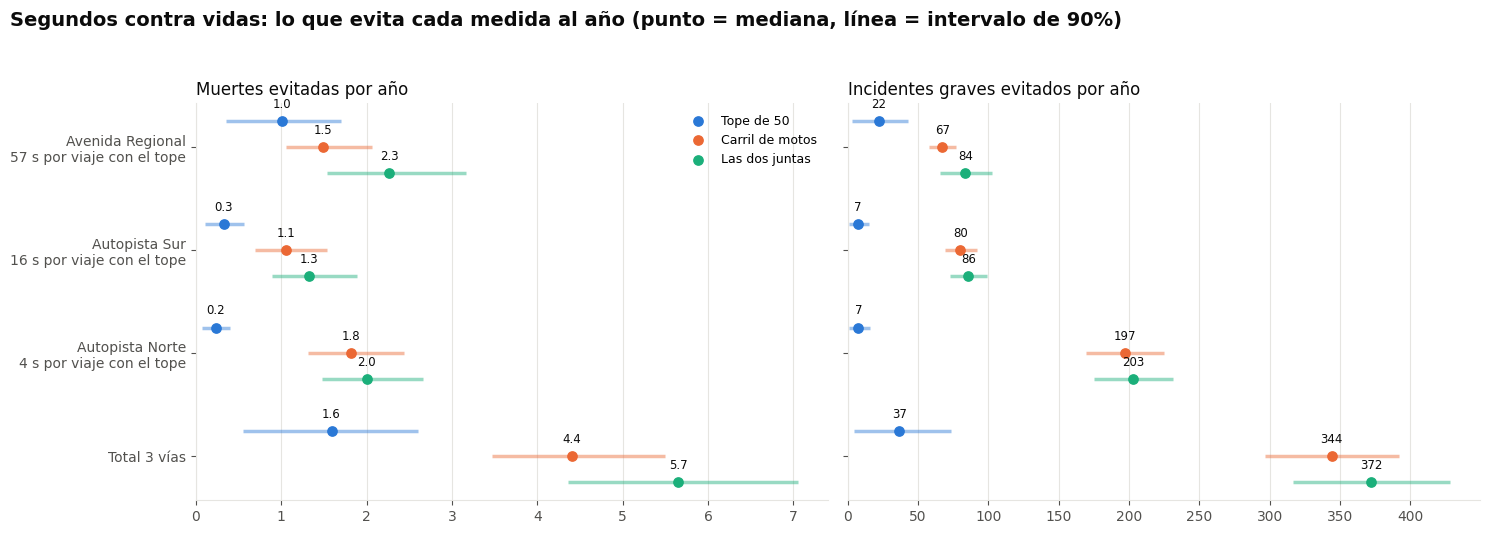

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
medidas = [("Tope de 50", AZUL), ("Carril de motos", NARANJA), ("Las dos juntas", "#1baf7a")]
vias = RAPIDAS + ["TOTAL"]
etiquetas = [f"{NOMBRE[c]}\n{segundos.loc[c, 'día']:.0f} s por viaje con el tope" if c in RAPIDAS
             else "Total 3 vías" for c in vias]
for ax, var, titulo in [(ax1, "muertes", "Muertes evitadas por año"), (ax2, "graves", "Incidentes graves evitados por año")]:
    for j, (m, col) in enumerate(medidas):
        y = np.arange(len(vias))[::-1] + (1 - j) * 0.25
        x = comparacion.xs(m, level="medida").reindex([NOMBRE.get(c, "Total 3 vías") for c in vias])
        lo, hi = x[f"{var} p5" if var == "muertes" else "graves p5"], x[f"{var} p95" if var == "muertes" else "graves p95"]
        centro = x["muertes evitadas/año" if var == "muertes" else "graves evitados/año"]
        ax.hlines(y, lo, hi, color=col, lw=2.5, alpha=0.45)
        ax.scatter(centro, y, color=col, s=45, zorder=3, label=m if ax is ax1 else None)
        for yi, ci in zip(y, centro):
            ax.text(ci, yi + 0.1, f"{ci:.1f}" if var == "muertes" else f"{ci:.0f}", ha="center", va="bottom",
                    fontsize=8.5, color=TINTA)
    ax.set_title(titulo, loc="left", fontsize=12, color=TINTA)
    ax.set_xlim(left=0); estilo(ax, eje="x")
ax1.set_yticks(np.arange(len(vias))[::-1], etiquetas)
ax1.legend(frameon=False, loc="upper right", fontsize=9)
fig.suptitle("Segundos contra vidas: lo que evita cada medida al año (punto = mediana, línea = intervalo de 90%)",
             x=0.01, ha="left", fontsize=14, weight="bold", color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

In [18]:
# Sensibilidad: Nilsson clásico, sin incertidumbre (bases promedio, cumplimiento total)
filas = []
for c in RAPIDAS:
    fn = float(fac.loc[c, "factor de noche"])
    rg_d, rm_d = reduccion(c, 2)[0], reduccion(c, 4)[0]
    md_, mn_ = muertos.loc[c, "día"] / anos, (muertos.loc[c, "noche"] + muertos.loc[c, "sin hora"]) / anos
    gd_, gn_ = graves.loc[c, "día"] / anos_itm, (graves.loc[c, "noche"] + graves.loc[c, "sin hora"]) / anos_itm
    ev_m = md_ * rm_d + mn_ * min(rm_d * fn, 0.95)
    ev_g = gd_ * rg_d + gn_ * min(rg_d * fn, 0.95)
    filas.append({"corredor": NOMBRE[c],
                  "muertes evitadas · Monte Carlo (mediana)": med(tope[c]["muertes"]),
                  "muertes evitadas · Nilsson 4": ev_m,
                  "graves evitados · Monte Carlo (mediana)": med(tope[c]["graves"]),
                  "graves evitados · Nilsson 2": ev_g,
                  "% de muertes · Monte Carlo (p5–p95)": f"{p5(tope[c]['pct_muertes']) * 100:.0f} a {p95(tope[c]['pct_muertes']) * 100:.0f}",
                  "% de muertes · Nilsson 4": ev_m / (md_ + mn_) * 100,
                  "Bogotá (%)": "22 a 37"})
sensibilidad = pd.DataFrame(filas).set_index("corredor")
sensibilidad.to_csv("data/processed/mc_sensibilidad.csv")
sensibilidad.round(1)

,muertes evitadas · Monte Carlo (mediana),muertes evitadas · Nilsson 4,graves evitados · Monte Carlo (mediana),graves evitados · Nilsson 2,% de muertes · Monte Carlo (p5–p95),% de muertes · Nilsson 4,Bogotá (%)
corredor,,,,,,,
Avenida Regional,1.0,2.1,21.8,56.7,6 a 25,32.6,22 a 37
Autopista Sur,0.3,0.7,7.3,20.2,2 a 8,10.9,22 a 37
Autopista Norte,0.2,0.5,7.4,20.9,1 a 4,4.9,22 a 37


**Conclusión.**
- **Las dos medidas juntas** evitarían **5,7 muertes por año** (intervalo de 90%: 4,4 a 7,1) y **372 incidentes graves por año** (316 a 428) en las 3 vías rápidas. Es una de cada cuatro muertes (5,7 de 23,8 por año) y uno de cada cuatro incidentes graves (372 de 1.419). Juntas no suman lo de cada una por separado, porque el carril actúa sobre lo que queda después del tope.
- **El carril de motos evita más en las 3 vías.** Salva 4,4 muertes por año, frente a 1,6 del tope, y 344 incidentes graves, frente a 37. La ventaja se mantiene en el escenario más favorable para el tope: con Nilsson, el tope llega a 3,3 muertes por año en total (2,1 en la Regional, 0,7 en la Autopista Sur y 0,5 en la Autopista Norte).
- **Cada vía tiene su problema y su medida:**
  - **Regional, un problema de velocidad:** el tope evita 1 muerte por año a cambio de 57 s por viaje. Es la única vía donde el tope pesa casi tanto como el carril (1,0 frente a 1,5), y juntos evitan 2,3 muertes por año.
  - **Autopista Norte, un problema de motos:** el tope casi no cambia nada (0,2 muertes, 4 s), y el carril evita 1,8 muertes y 197 incidentes graves por año.
  - **Autopista Sur, entre las dos:** el carril evita 1,1 muertes y el tope 0,3, a cambio de 16 s por viaje.
- **Prueba de sensatez con Bogotá (−22% a −37%):**
  - **Regional:** el tope reduce entre 6% y 25% de sus muertes en el Monte Carlo, y 33% con Nilsson. Bogotá cae en la parte alta de ese rango.
  - **Autopistas:** quedan muy por debajo de Bogotá (1% a 11%), y es lo esperado: en Bogotá el límite bajó de 60 a 50 en vías donde todos iban rápido, y aquí el tope solo actúa donde hoy se pasa de 50.

**Decisión.** La recomendación es **dos problemas, dos medidas**: el tope de 50 con control permanente en la Regional, y el carril exclusivo de motos en las 3 vías rápidas, empezando por la Autopista Norte. El orden entre las medidas no depende del exponente: el carril gana incluso con Nilsson. Las cifras se presentan con su intervalo, y el carril con su supuesto principal a la vista: que el efecto de Malasia se repita en Medellín.

## 6 · Resumen

**Pregunta.** En las vías rápidas de Medellín, ¿cuántas vidas y cuántos incidentes graves al año evitaría un tope de 50 km/h (como Bogotá) o un carril exclusivo de motos (como Malasia), y cuántos segundos por viaje costaría?

**Datos.**
- Muertos del Distrito (2019–2024) e incidentes graves del ITM corregidos por cobertura (D32), asignados con el mismo método que todo el proyecto (D27, D30).
- Víctimas en moto de MEData (2014–2021).
- Velocidad de día de Google Traffic (2017–2019) y de noche del SIMM (2020, solo como razón noche/día; D36).
- Exponentes entre el piso de Medellín y Elvik urbano (D37), y la reducción de Malasia.
- 10.000 simulaciones con semilla fija.

**Resultados**
1. **En las 3 vías rápidas mueren unas 24 personas por año, y la mitad de noche.** Son la Regional, la Autopista Sur y la Autopista Norte, que concentran el 49% de los muertos de los 12 corredores. Ahí cada incidente grave es más letal que en las arterias: 1 muerto por cada 43 en la Regional, frente a 1 por cada 144 en El Poblado.
2. **El tope de 50 km/h, con control permanente, evitaría 1,6 muertes por año (0,6 a 2,6) y 37 incidentes graves.** Casi todo el beneficio está en la Regional: 1 muerte por año, el 16% de sus muertes, a cambio de **57 segundos por viaje**. En la Autopista Norte casi no cambia nada (0,2 muertes, 4 s), porque allí poca gente pasa de 50.
3. **El carril exclusivo de motos evitaría 4,4 muertes por año (3,5 a 5,5) y 344 incidentes graves.** La vía donde más rinde es la Autopista Norte (1,8 muertes y 197 incidentes graves), justo donde el tope no sirve. En las 3 vías, más del 80% de las víctimas va en moto.
4. **Juntas, las dos medidas evitarían 5,7 muertes por año (4,4 a 7,1) y 372 incidentes graves: una de cada cuatro.**
5. **El orden no depende del supuesto más dudoso.** El carril salva más que el tope incluso con Nilsson, el techo para el tope (3,3 muertes por año).
6. **Prueba de sensatez:** en la Regional, Bogotá (−22% a −37%) cae en la parte alta de nuestro intervalo (6% a 25%; 33% con Nilsson). En las autopistas quedamos muy por debajo, y es lo esperado, porque aquí el tope solo actúa donde hoy se pasa de 50.

**Recomendación: dos problemas, dos medidas.**
- **Regional · un problema de velocidad:** tope de 50 km/h con control permanente (cámaras o puestos de control con multas, como Bogotá). Cuesta menos de un minuto por viaje.
- **Autopista Norte, Autopista Sur y Regional · un problema de motos:** carril exclusivo de motos, empezando por la Autopista Norte.

**Límites**
- **El tope supone control permanente.** El cumplimiento se sorteó entre 85% y 100% (supuesto nuestro; D38). Sin control el efecto sería mucho menor.
- **El carril descansa sobre un solo estudio** (Malasia, 1995, antes y después, sin grupo de control). Su intervalo es estrecho porque el rango del estudio lo es, no porque el resultado sea seguro. Aplicado a las muertes, supone que bajan en la misma proporción que los accidentes.
- **El exponente es conservador a propósito:** la evidencia de Medellín es débil (notebooks 03 y 04).
- **Los segundos son por viaje, no horas totales de la ciudad,** y solo valen para quien cumple el tope. En la Autopista Norte, calculando por sentido, el exceso es mayor (D39).
- **Los periodos no coinciden:** velocidades de 2017–2019, muertos de 2019–2024 y motos de 2014–2021.
- **Lo que no se estimó:** el costo del carril en espacio e infraestructura, y si el tráfico se desvía a otras vías.

**Qué pasa al notebook final**
- **Paso 11, "segundos contra vidas":** la gráfica de la sección 5.
- **Cierre del acto II, "dos problemas, dos medidas":** la Regional como problema de velocidad y la Autopista Norte como problema de motos.
- **Paso 12, la recomendación,** con sus límites a la vista.